# Main-text and supplementary summary figures (PDF and PNG)

Draws Figures 3, 5 and 6 of the main text and the summary figures of the Supplement from the results workbooks. Every figure is saved **twice**: a vector **PDF** (sharp at any size, for the journal) and a 300 dpi **PNG** (for Word).

Needs, in the same folder: `synthetic_v2_results.xlsx`, `SH-ITA_final_PM_results.xlsx`, `SH-ITA_PET_sensitivity.xlsx`.
(The SH-ITA scatter plots, including main-text Figure 4, are made by `SH-ITA_final_PM.ipynb`.)

In [3]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
OUT = 'main_figures'; os.makedirs(OUT, exist_ok=True)
SYN = 'synthetic_v2_outputs/synthetic_v2_results.xlsx'; FIN = 'sh_ita_outputs/SH-ITA_final_PM_results.xlsx'; PETX = 'sh_ita_outputs/SH-ITA_PET_sensitivity.xlsx'
plt.rcParams.update({'font.size': 9, 'axes.titlesize': 9, 'pdf.fonttype': 42})
def save(fig, name):
    fig.savefig(os.path.join(OUT, name + '.pdf'), bbox_inches='tight'); fig.savefig(os.path.join(OUT, name + '.png'), dpi=300, bbox_inches='tight')
    print('saved', name, '(.pdf and .png)')

## Figure 3 (main) and supplementary power figure: detection rates from the synthetic experiments

saved Fig3_synthetic_power (.pdf and .png)


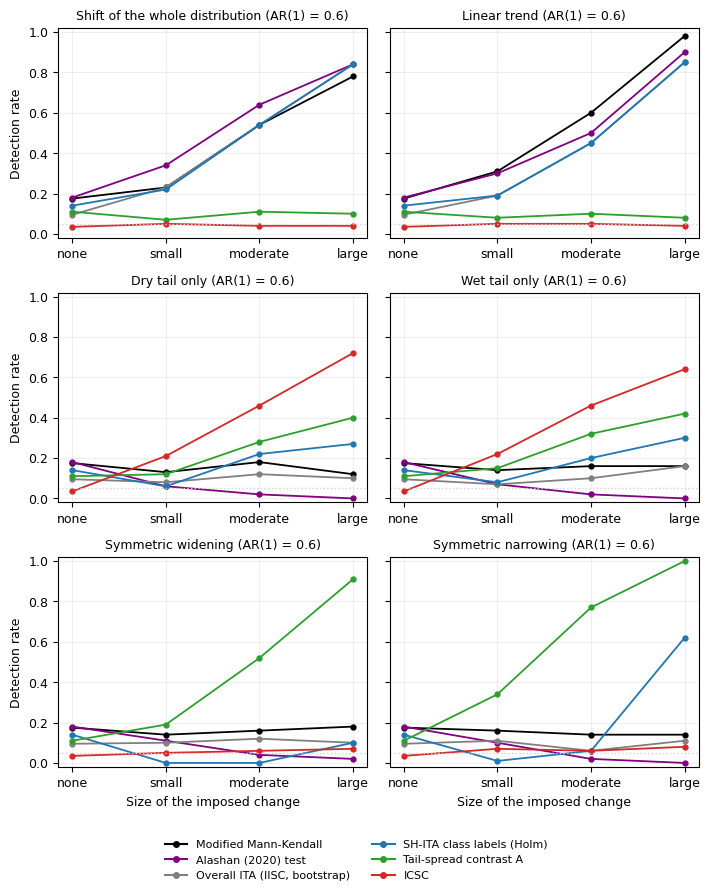

saved FigS_synthetic_power_all (.pdf and .png)


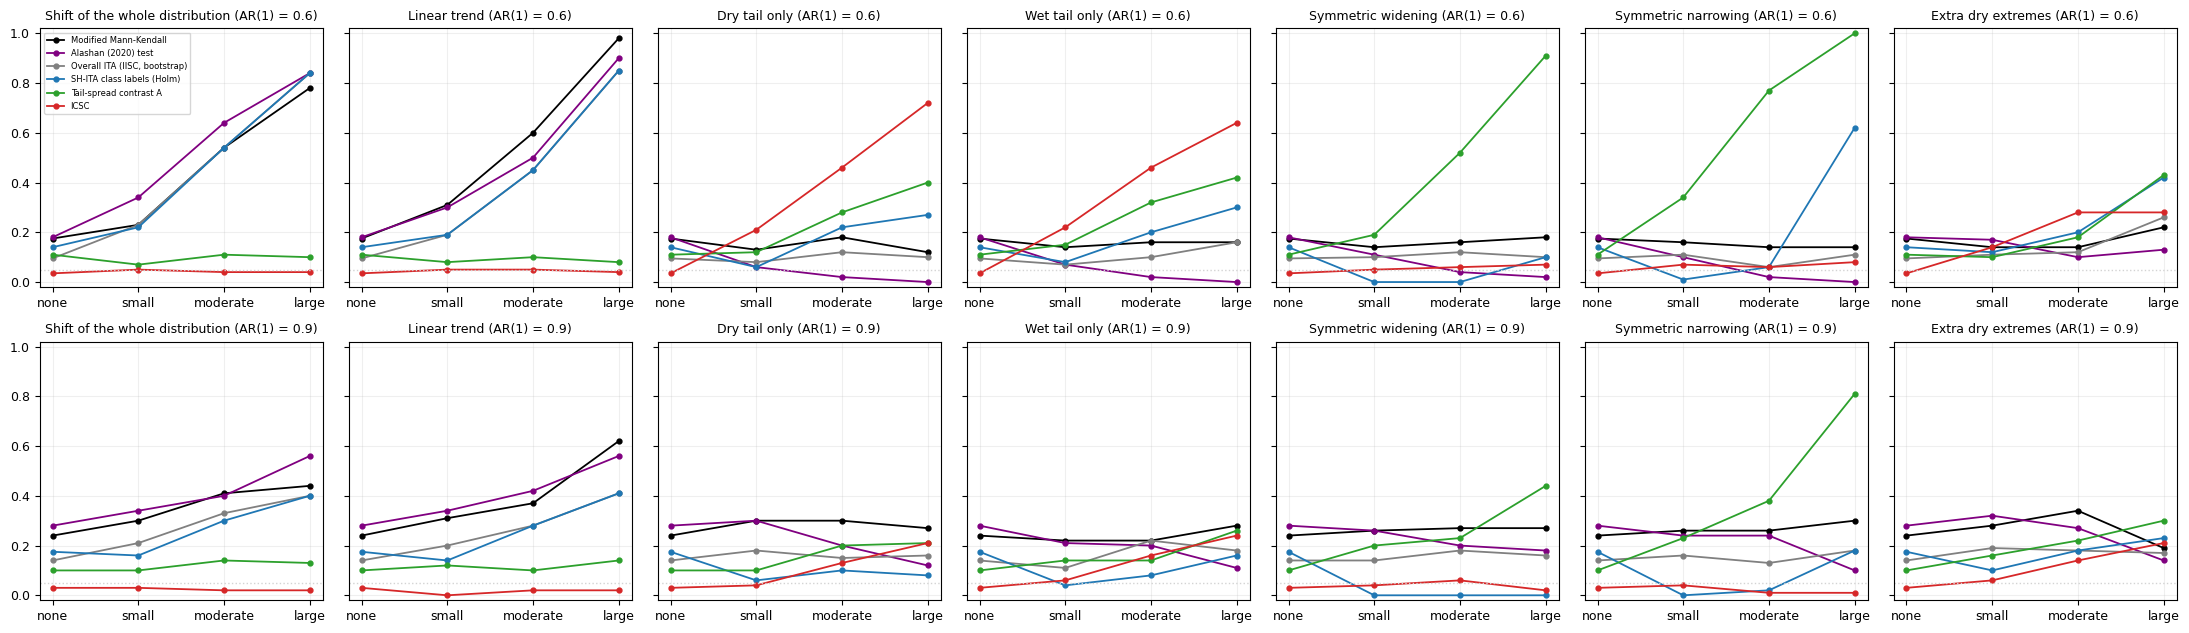

saved FigS_false_positive_rates (.pdf and .png)


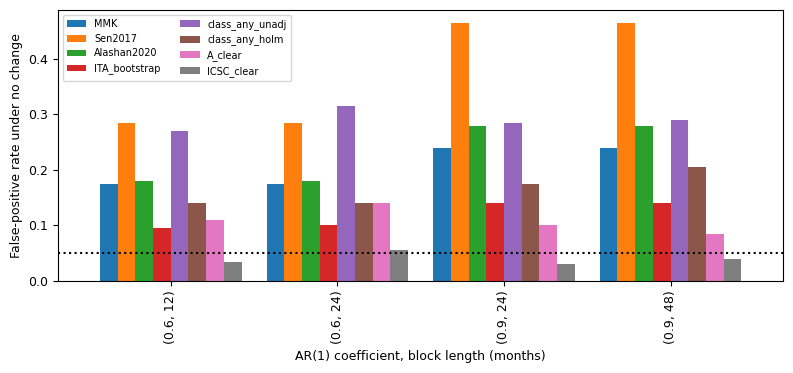

In [4]:
det = pd.read_excel(SYN, 'Detection rates'); fpr = pd.read_excel(SYN, 'False-positive rates')
LV = ['none', 'small', 'moderate', 'large']
M = {'MMK': ('k', 'Modified Mann-Kendall'), 'Alashan2020': ('purple', 'Alashan (2020) test'), 'ITA_bootstrap': ('gray', 'Overall ITA (IISC, bootstrap)'),
     'diag_holm': ('tab:blue', 'SH-ITA class labels (Holm)'), 'A_clear': ('tab:green', 'Tail-spread contrast A'), 'ICSC_clear': ('tab:red', 'ICSC')}
NULLMAP = {'MMK': 'MMK', 'Alashan2020': 'Alashan2020', 'ITA_bootstrap': 'ITA_bootstrap', 'diag_holm': 'class_any_holm', 'A_clear': 'A_clear', 'ICSC_clear': 'ICSC_clear'}
PRIM = {0.6: 12, 0.9: 24}
TITLE = {'location': 'Shift of the whole distribution', 'linear_trend': 'Linear trend', 'dry_tail': 'Dry tail only', 'wet_tail': 'Wet tail only',
         'widen': 'Symmetric widening', 'narrow': 'Symmetric narrowing', 'extreme_dry': 'Extra dry extremes'}
def panel(ax, phi, scen):
    L = PRIM[phi]; sub = det[(det.phi == phi) & (det.L == L) & (det.scenario == scen)].set_index('level')
    null = fpr[(fpr.phi == phi) & (fpr.L == L)].iloc[0]
    for k, (c, lab) in M.items():
        y = [null[NULLMAP[k]]] + [sub.loc[l, k] for l in LV[1:]]; ax.plot(range(4), y, 'o-', color=c, ms=3.5, lw=1.3, label=lab)
    ax.axhline(0.05, color='lightgray', ls=':', lw=1); ax.set_ylim(-0.02, 1.02); ax.set_xticks(range(4)); ax.set_xticklabels(['none', 'small', 'moderate', 'large'])
    ax.set_title(f'{TITLE[scen]} (AR(1) = {phi})'); ax.grid(alpha=0.2)
main = ['location', 'linear_trend', 'dry_tail', 'wet_tail', 'widen', 'narrow']
fig, axes = plt.subplots(3, 2, figsize=(7.2, 8.6), sharey=True)
for ax, s in zip(axes.ravel(), main): panel(ax, 0.6, s)
for ax in axes[:, 0]: ax.set_ylabel('Detection rate')
axes[2, 0].set_xlabel('Size of the imposed change'); axes[2, 1].set_xlabel('Size of the imposed change')
h = [Line2D([0], [0], color=c, marker='o', ms=4, label=l) for c, l in M.values()]
fig.legend(handles=h, loc='lower center', ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.04)); fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, 'Fig3_synthetic_power'); plt.show()
fig, axes = plt.subplots(2, 7, figsize=(22, 6.4), sharey=True)
for i, phi in enumerate((0.6, 0.9)):
    for j, s in enumerate(['location', 'linear_trend', 'dry_tail', 'wet_tail', 'widen', 'narrow', 'extreme_dry']): panel(axes[i, j], phi, s)
axes[0, 0].legend(fontsize=6); fig.tight_layout(); save(fig, 'FigS_synthetic_power_all'); plt.show()
fig, ax = plt.subplots(figsize=(8, 3.8)); cols = ['MMK', 'Sen2017', 'Alashan2020', 'ITA_bootstrap', 'class_any_unadj', 'class_any_holm', 'A_clear', 'ICSC_clear']
f2 = fpr.set_index(['phi', 'L'])[cols]; f2.plot.bar(ax=ax, width=0.85); ax.axhline(0.05, color='k', ls=':'); ax.set_ylabel('False-positive rate under no change')
ax.set_xlabel('AR(1) coefficient, block length (months)'); ax.legend(fontsize=7, ncol=2); fig.tight_layout(); save(fig, 'FigS_false_positive_rates'); plt.show()

## Figure 5 (main): agreement between methods on the 32 series

saved Fig5_method_agreement (.pdf and .png)


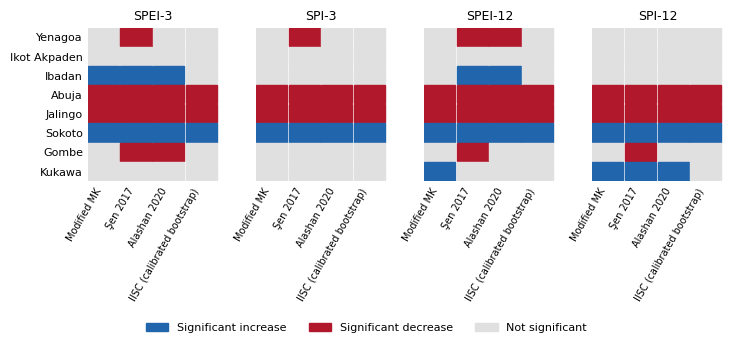

In [5]:
E = pd.read_excel(FIN, 'Final (primary block)'); E['sign'] = np.sign(E['IISC [95% CI]'].str.split().str[0].astype(float))
meth = [('MMK sig', 'Modified MK'), ('Sen2017 sig', 'Şen 2017'), ('Alashan2020 sig', 'Alashan 2020'), ('IISC clear (calibrated)', 'IISC (calibrated bootstrap)')]
order = ['Yenagoa', 'Ikot Akpaden', 'Ibadan', 'Abuja', 'Jalingo', 'Sokoto', 'Gombe', 'Kukawa']
idxs = ['SPEI-3', 'SPI-3', 'SPEI-12', 'SPI-12']
fig, axes = plt.subplots(1, 4, figsize=(7.4, 3.4))
for ax, ix in zip(axes, idxs):
    d = E[E.Index == ix].set_index('Location').loc[order]
    for j, (col, lab) in enumerate(meth):
        for i, loc in enumerate(order):
            sig = bool(d.loc[loc, col]); sg = d.loc[loc, 'sign']
            color = ('#2166ac' if sg > 0 else '#b2182b') if sig else '#e0e0e0'
            ax.add_patch(plt.Rectangle((j, i), 0.95, 0.95, color=color))
    ax.set_xlim(0, 4); ax.set_ylim(len(order), 0); ax.set_xticks(np.arange(4) + 0.47); ax.set_xticklabels([m[1] for m in meth], rotation=60, ha='right', fontsize=7)
    ax.set_title(ix); ax.set_yticks(np.arange(len(order)) + 0.47); ax.set_yticklabels(order if ax is axes[0] else [], fontsize=8)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0)
fig.legend(handles=[Patch(color='#2166ac', label='Significant increase'), Patch(color='#b2182b', label='Significant decrease'), Patch(color='#e0e0e0', label='Not significant')],
           loc='lower center', ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1)); save(fig, 'Fig5_method_agreement'); plt.show()

## Figure 6 (main): effect of the PET formulation on the 12-month SPEI shift

saved Fig6_PET_sensitivity (.pdf and .png)


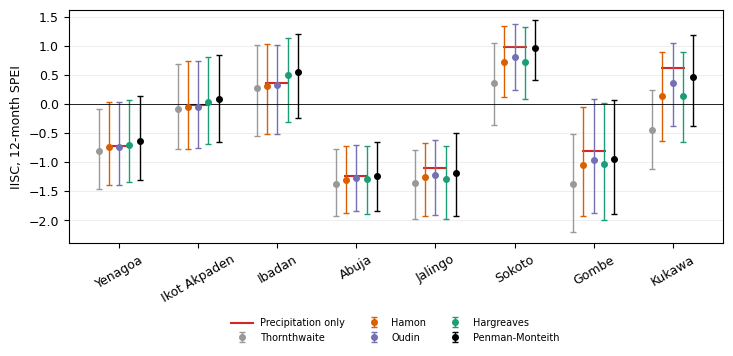

saved FigS_PET_sensitivity_3month (.pdf and .png)


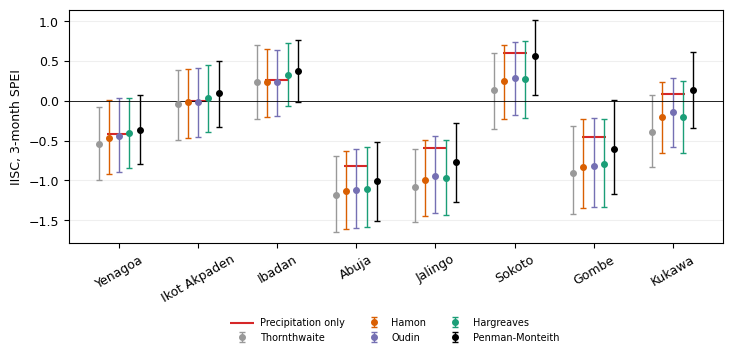

In [6]:
S0 = pd.read_excel(PETX, 'SH-ITA by PET and variant'); S0 = S0[S0.window.str.startswith('B')]
pets = ['Thornthwaite', 'Hamon', 'Oudin', 'Hargreaves', 'Penman-Monteith']; colors = dict(zip(pets, ['#999999', '#d95f02', '#7570b3', '#1b9e77', '#000000']))
def pet_figure(scale, name):
    S = S0[S0.scale == scale]; act = S[S.variant == 'actual PET']; ponly = S[S.variant == 'P only'].set_index('location').IISC
    fig, ax = plt.subplots(figsize=(7.4, 3.8)); locs = [o for o in order if o in set(act.location)]
    for k, p in enumerate(pets):
        d = act[act.PET == p].set_index('location').loc[locs]; x = np.arange(len(locs)) + (k - 2) * 0.13
        ax.errorbar(x, d.IISC, yerr=[d.IISC - d.IISC_lo, d.IISC_hi - d.IISC], fmt='o', ms=4, color=colors[p], capsize=2, lw=1, label=p)
    ax.scatter(np.arange(len(locs)), [ponly[l] for l in locs], marker='_', s=300, color='tab:red', zorder=0, label='Precipitation only')
    ax.axhline(0, color='k', lw=0.6); ax.set_xticks(range(len(locs))); ax.set_xticklabels(locs, rotation=30); ax.set_ylabel(f'IISC, {scale}-month SPEI')
    ax.legend(fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.28), frameon=False); ax.grid(alpha=0.2, axis='y'); fig.tight_layout(); save(fig, name); plt.show()
pet_figure(12, 'Fig6_PET_sensitivity'); pet_figure(3, 'FigS_PET_sensitivity_3month')